In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [18]:
from google.colab import files
uploaded = files.upload()

Saving Anemia Dataset.xlsx to Anemia Dataset (1).xlsx


In [19]:
df = pd.read_excel("/content/Anemia Dataset.xlsx")

In [20]:
df.shape

(1000, 9)

In [21]:
df.head(10)

,Gender,Age,Hb,RBC,PCV,MCV,MCH,MCHC,Decision_Class
0,f,32,10.9,4.26,34.2,80.2,25.5,31.8,1
1,f,45,9.6,3.64,29.9,82.1,26.4,32.2,1
2,f,38,10.1,3.70,32.4,87.6,27.4,31.3,1
3,m,37,11.0,3.93,33.6,85.3,27.9,32.7,1
4,f,50,12.1,4.16,36.5,87.9,29.2,33.2,0
5,f,40,10.4,3.59,30.4,84.5,27.7,32.7,1
6,f,32,6.8,1.99,15.4,77.4,24.0,31.0,1
7,m,18,11.6,4.06,35.5,87.4,28.6,32.8,1
8,m,38,12.0,4.38,36.3,82.8,27.5,33.2,0
9,f,50,11.7,4.35,36.6,84.0,26.9,32.0,1


In [22]:
df.columns.tolist()

['Gender', 'Age', 'Hb', 'RBC', 'PCV', 'MCV', 'MCH', 'MCHC', 'Decision_Class']

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          1000 non-null   object 
 1   Age             1000 non-null   int64  
 2   Hb              1000 non-null   float64
 3   RBC             1000 non-null   float64
 4   PCV             1000 non-null   float64
 5   MCV             1000 non-null   float64
 6   MCH             1000 non-null   float64
 7   MCHC            1000 non-null   float64
 8   Decision_Class  1000 non-null   int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 70.4+ KB


In [24]:
df.duplicated().sum()

np.int64(28)

In [25]:
df.drop_duplicates(inplace=True)

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df.value_counts()

Gender  Age  Hb    RBC   PCV   MCV   MCH   MCHC  Decision_Class
m       85   10.8  3.63  28.6  78.9  28.0  35.5  1                 1
f       18   10.2  3.74  29.3  78.4  28.8  36.8  1                 1
                   4.29  27.6  64.3  22.5  35.1  1                 1
             10.3  4.04  32.0  79.1  25.6  32.3  1                 1
             10.4  3.43  25.9  75.6  27.3  36.1  1                 1
                                                                  ..
             12.6  4.67  36.3  77.7  26.9  34.6  0                 1
             12.1  4.41  33.8  76.8  27.5  35.8  0                 1
                   3.68  33.5  90.9  32.8  36.1  0                 1
             12.0  3.95  33.6  85.0  30.5  35.9  0                 1
             11.6  4.34  32.8  75.6  26.7  35.4  1                 1
Name: count, Length: 972, dtype: int64

In [28]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')


In [29]:
df.columns

Index(['gender', 'age', 'hb', 'rbc', 'pcv', 'mcv', 'mch', 'mchc',
       'decision_class'],
      dtype='object')

In [30]:
df = df.drop_duplicates().copy()

In [35]:
df["decision_class"] = pd.to_numeric(df["decision_class"], errors="coerce")

In [36]:
df = df.dropna(subset=["decision_class"])

In [38]:
df.head(10)

,gender,age,hb,rbc,pcv,mcv,mch,mchc,decision_class
0,f,32,10.9,4.26,34.2,80.2,25.5,31.8,1
1,f,45,9.6,3.64,29.9,82.1,26.4,32.2,1
2,f,38,10.1,3.70,32.4,87.6,27.4,31.3,1
3,m,37,11.0,3.93,33.6,85.3,27.9,32.7,1
4,f,50,12.1,4.16,36.5,87.9,29.2,33.2,0
5,f,40,10.4,3.59,30.4,84.5,27.7,32.7,1
6,f,32,6.8,1.99,15.4,77.4,24.0,31.0,1
7,m,18,11.6,4.06,35.5,87.4,28.6,32.8,1
8,m,38,12.0,4.38,36.3,82.8,27.5,33.2,0
9,f,50,11.7,4.35,36.6,84.0,26.9,32.0,1


In [39]:
df.isnull().sum()

,0
gender,0
age,0
hb,0
rbc,0
pcv,0
mcv,0
mch,0
mchc,0
decision_class,0


In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

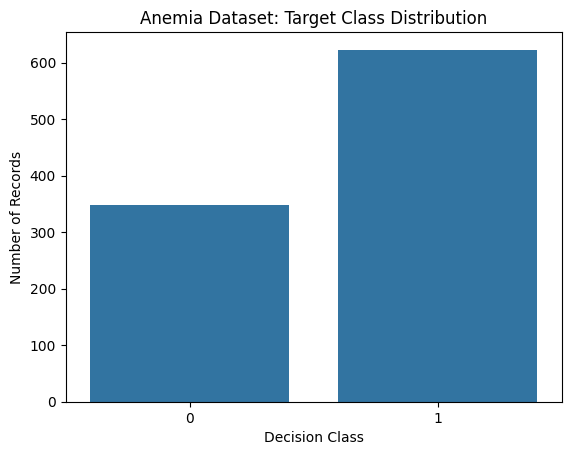

In [44]:
sns.countplot(data=df, x="decision_class")
plt.title("Anemia Dataset: Target Class Distribution")
plt.xlabel("Decision Class")
plt.ylabel("Number of Records")
plt.show()

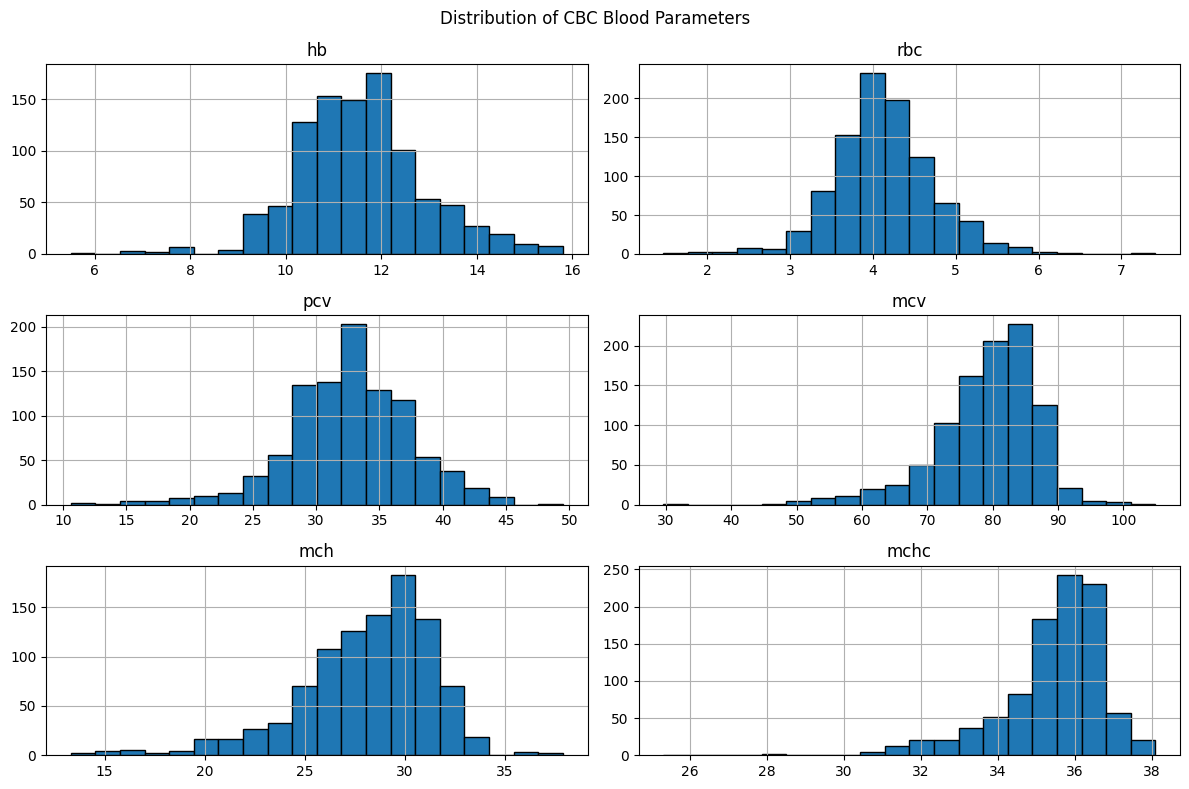

In [46]:
features = ["hb", "rbc", "pcv", "mcv", "mch", "mchc"]

df[features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of CBC Blood Parameters")
plt.tight_layout()
plt.show()

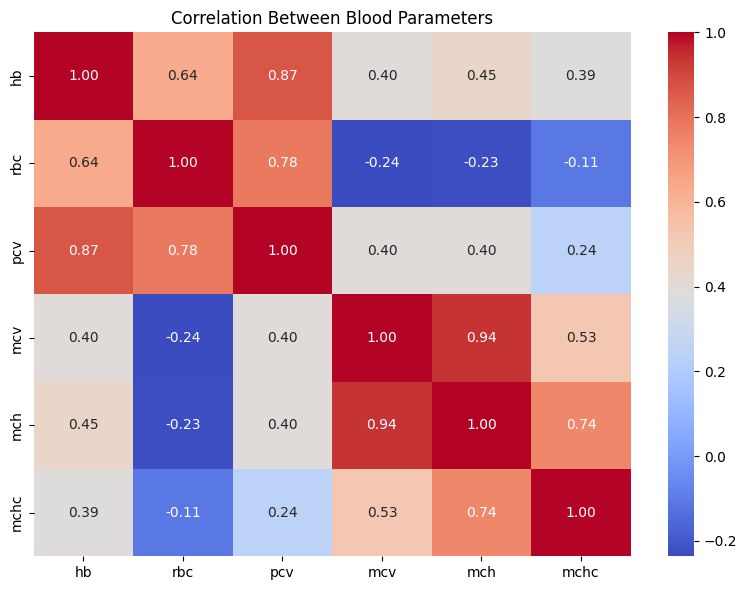

In [47]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Blood Parameters")
plt.tight_layout()
plt.show()

In [50]:
features = ["hb", "rbc", "pcv", "mcv", "mch", "mchc"]

In [52]:
X = df[features]
y = df["decision_class"]

In [53]:
X.head()

,hb,rbc,pcv,mcv,mch,mchc
0,10.9,4.26,34.2,80.2,25.5,31.8
1,9.6,3.64,29.9,82.1,26.4,32.2
2,10.1,3.70,32.4,87.6,27.4,31.3
3,11.0,3.93,33.6,85.3,27.9,32.7
4,12.1,4.16,36.5,87.9,29.2,33.2


In [54]:
y.head()

,decision_class
0,1
1,1
2,1
3,1
4,0


In [57]:
y.value_counts()

,count
decision_class,
1,623
0,349


In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

In [62]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


In [63]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

In [64]:
clf = {"SVC": SVC(),
       "Random Forest": RandomForestClassifier(),
       "KNN": KNeighborsClassifier(),
       "Decision Tree": DecisionTreeClassifier(),
       "Naive Bayes": GaussianNB()}

In [72]:
svc_clf = SVC()
svc_clf.fit(X_train, y_train)

svc_pred = svc_clf.predict(X_test)


In [73]:
svc_pred

array([1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0,

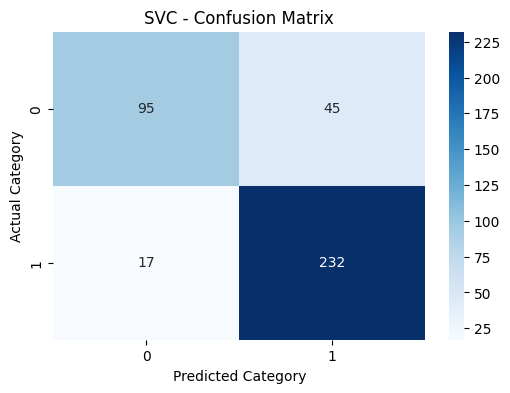

In [74]:
cm = confusion_matrix(y_test, svc_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("SVC - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

In [76]:
rf_clf = RandomForestClassifier()
rf_clf.fit(X_train, y_train)

rf_pred = rf_clf.predict(X_test)

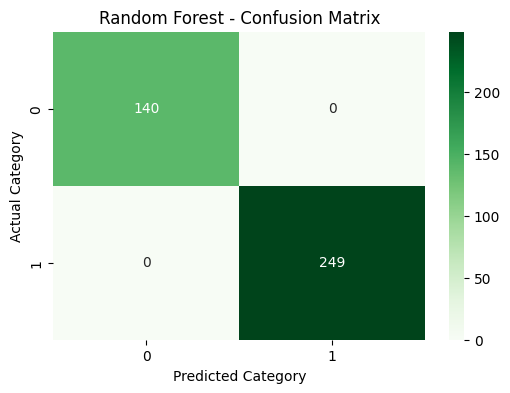

In [77]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

In [78]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_train)

knn_pred = knn_clf.predict(X_test)


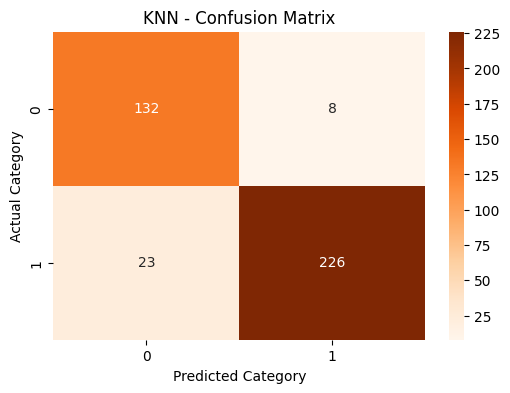

In [79]:
cm = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges")
plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

In [81]:
dt_clf = DecisionTreeClassifier()
dt_clf.fit(X_train, y_train)

dt_pred = dt_clf.predict(X_test)

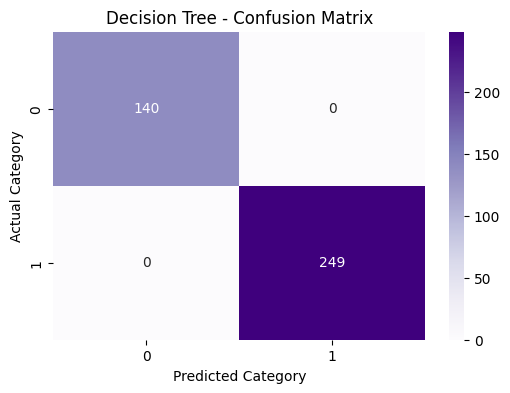

In [85]:
cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples")
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

In [86]:
nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)

nb_pred = nb_clf.predict(X_test)


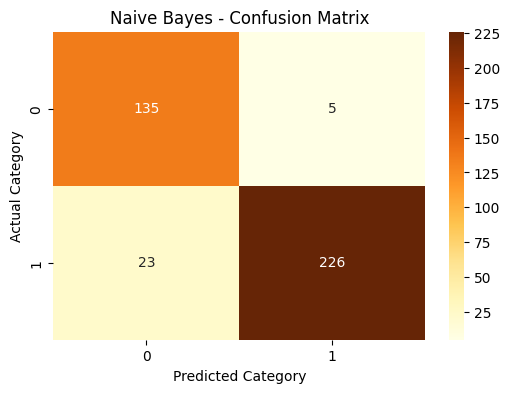

In [87]:
cm = confusion_matrix(y_test, nb_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlOrBr")
plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()

<Figure size 800x500 with 0 Axes>

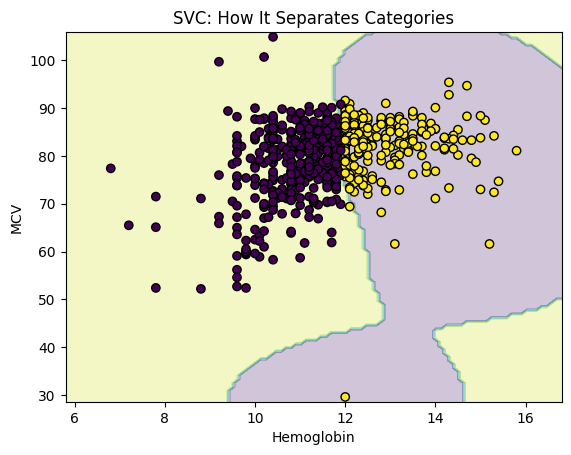

In [89]:
from sklearn.pipeline import make_pipeline
from sklearn.inspection import DecisionBoundaryDisplay

features = ["hb", "mcv"]
X_2d = X_train[features]

svc_viz = make_pipeline(StandardScaler(), SVC())
svc_viz.fit(X_2d, y_train)

plt.figure(figsize=(8, 5))

DecisionBoundaryDisplay.from_estimator(
    svc_viz, X_2d, response_method="predict", alpha=0.25
)

plt.scatter(
    X_2d["hb"],
    X_2d["mcv"],
    c=pd.factorize(y_train)[0],
    edgecolors="black"
)

plt.xlabel("Hemoglobin")
plt.ylabel("MCV")
plt.title("SVC: How It Separates Categories")
plt.show()

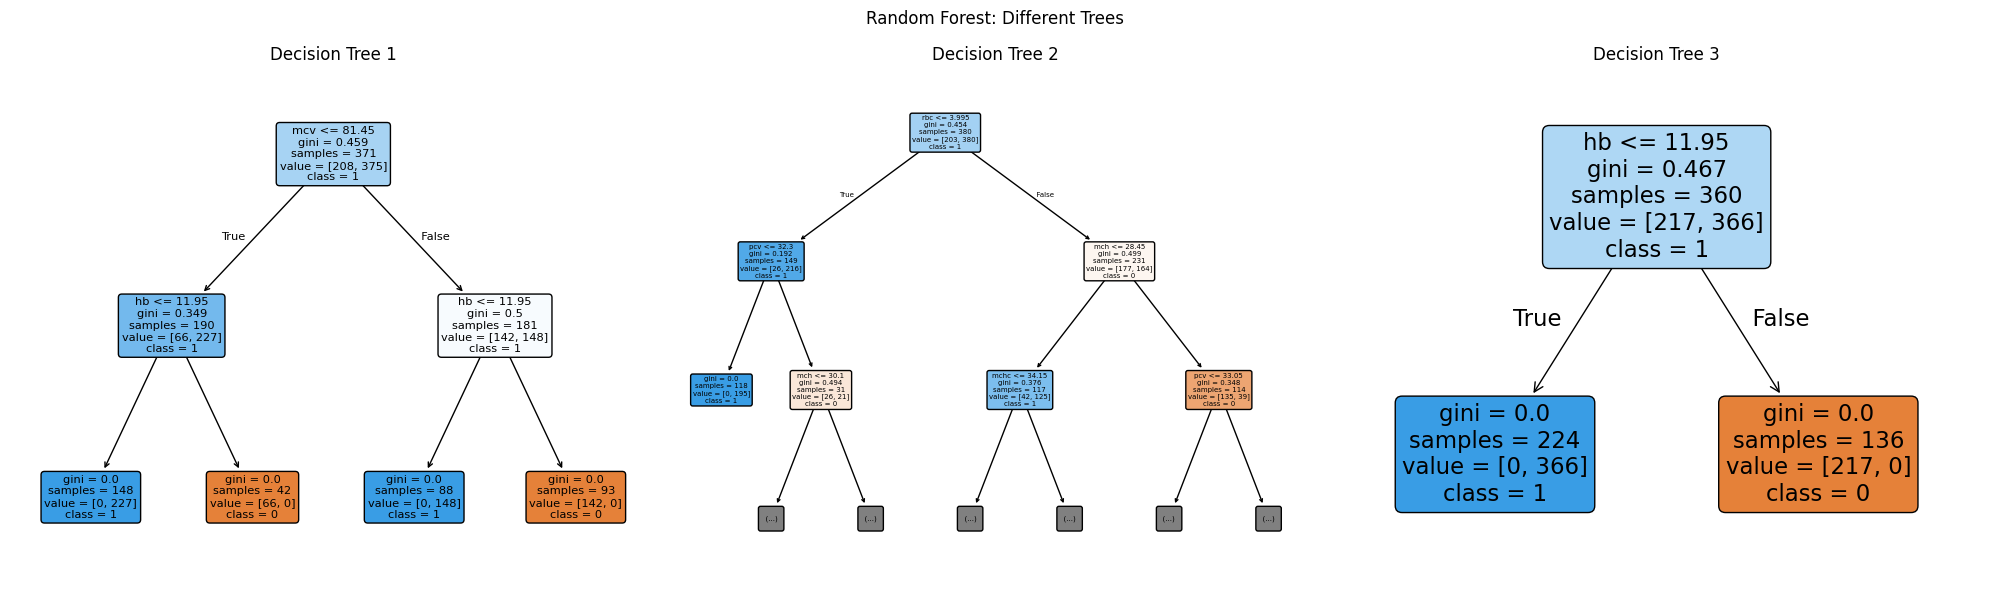

In [91]:
from sklearn.tree import plot_tree

rf_viz = clf["Random Forest"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, ax in enumerate(axes):
    plot_tree(
        rf_viz.estimators_[i],
        feature_names=list(X_train.columns),
        class_names=[str(c) for c in rf_viz.classes_],
        filled=True,
        rounded=True,
        max_depth=2,
        ax=ax
    )
    ax.set_title(f"Decision Tree {i + 1}")

plt.suptitle("Random Forest: Different Trees")
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

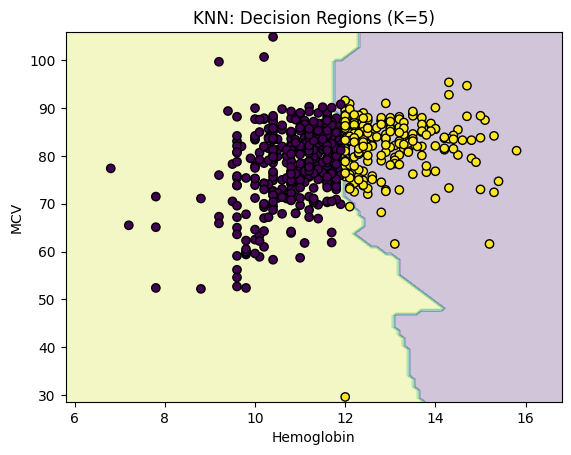

In [93]:
features = ["hb", "mcv"]
X_2d = X_train[features]

knn_viz = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_viz.fit(X_2d, y_train)

plt.figure(figsize=(8, 5))

DecisionBoundaryDisplay.from_estimator(
    knn_viz, X_2d, response_method="predict", alpha=0.25
)

plt.scatter(
    X_2d["hb"],
    X_2d["mcv"],
    c=pd.factorize(y_train)[0],
    edgecolors="black"
)

plt.xlabel("Hemoglobin")
plt.ylabel("MCV")
plt.title("KNN: Decision Regions (K=5)")
plt.show()

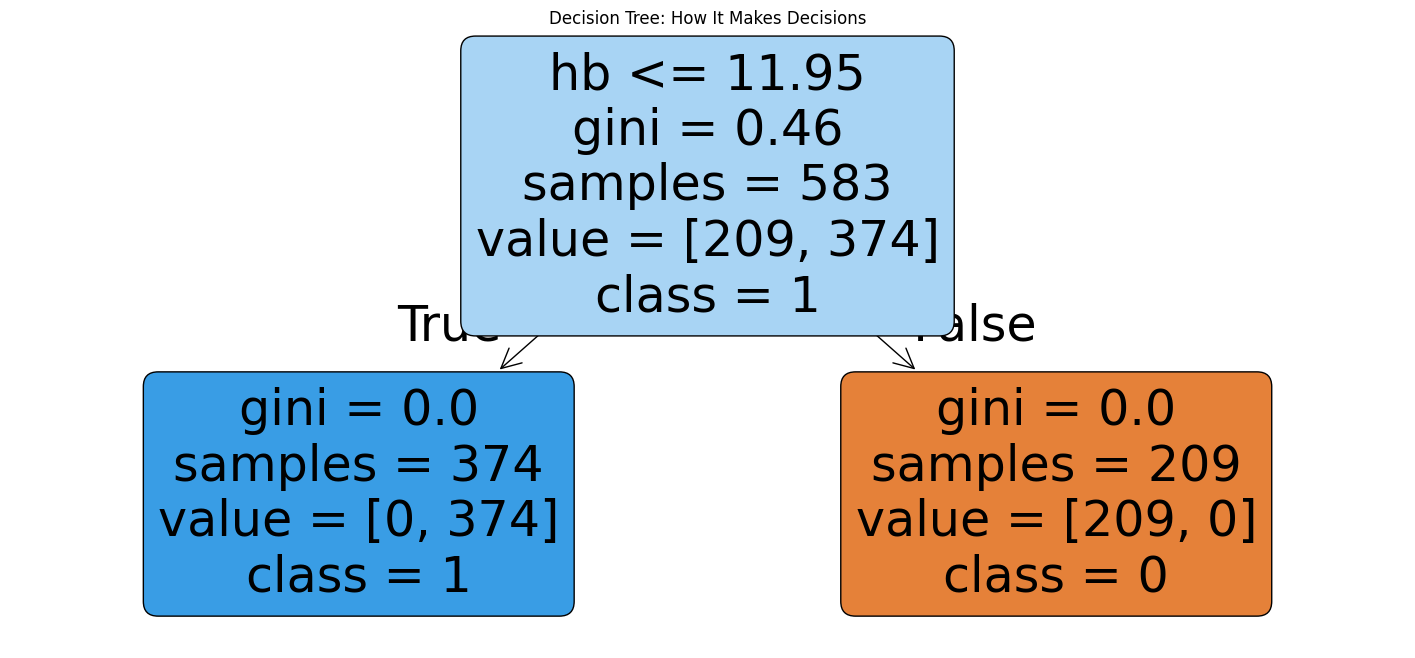

In [95]:
from sklearn.tree import plot_tree

dt_viz = clf["Decision Tree"]

plt.figure(figsize=(18, 8))

plot_tree(
    dt_viz,
    feature_names=list(X_train.columns),
    class_names=[str(c) for c in dt_viz.classes_],
    filled=True,
    rounded=True
)

plt.title("Decision Tree: How It Makes Decisions")
plt.show()

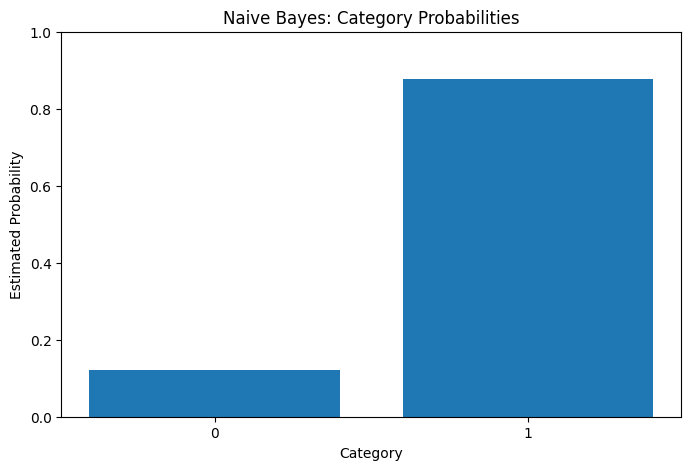

Actual category: 1
Predicted category: 1


In [97]:
nb_viz = clf["Naive Bayes"]

sample = X_test.iloc[[0]]
probabilities = nb_viz.predict_proba(sample)[0]

plt.figure(figsize=(8, 5))

plt.bar(
    [str(c) for c in nb_viz.classes_],
    probabilities
)

plt.xlabel("Category")
plt.ylabel("Estimated Probability")
plt.title("Naive Bayes: Category Probabilities")
plt.ylim(0, 1)
plt.show()

print("Actual category:", y_test.iloc[0])
print("Predicted category:", nb_viz.predict(sample)[0])

In [99]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []
predictions = {}

for name, model in clf.items():

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,SVC,0.8406,0.8414,0.8406,0.8360
1,Random Forest,1.0000,1.0000,1.0000,1.0000
2,KNN,0.9203,0.9247,0.9203,0.9211
3,Decision Tree,1.0000,1.0000,1.0000,1.0000
4,Naive Bayes,0.9280,0.9338,0.9280,0.9288


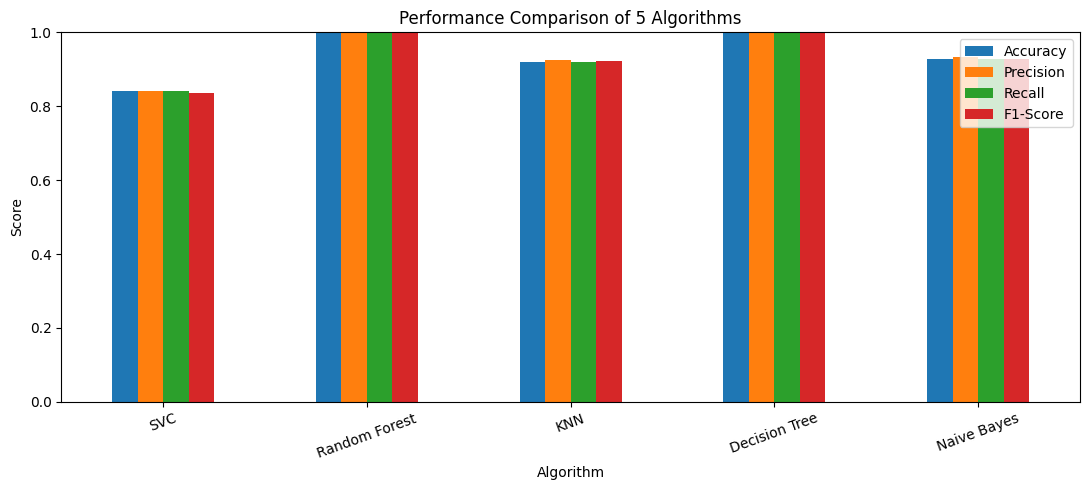

In [101]:
results_df.plot(
    x="Algorithm",
    y=["Accuracy", "Precision", "Recall", "F1-Score"],
    kind="bar",
    figsize=(11, 5)
)

plt.title("Performance Comparison of 5 Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [104]:
best_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Algorithm"
]

best_model = clf[best_name]

print("Best Algorithm:", best_name)
print("Best F1 Score:", round(
    results_df.loc[
        results_df["Algorithm"] == best_name, "F1-Score"
    ].iloc[0], 3
))

Best Algorithm: Random Forest
Best F1 Score: 1.0


In [106]:
import joblib

joblib.dump(best_model, "anemia_model.pkl")


['anemia_model.pkl']

In [107]:
from google.colab import files

files.download("/content/anemia_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [108]:
!pip install -q gradio

In [112]:
models = {
    "SVC": svc_clf,
    "Random Forest": rf_clf,
    "KNN": knn_clf,
    "Decision Tree": dt_clf,
    "Naive Bayes": nb_clf
}

In [116]:
import gradio as gr
import pandas as pd
import numpy as np

feature_names = list(X_train.columns)

def predict_anemia(algorithm, hb, rbc, pcv, mcv, mch, mchc):

    try:
        values = {
            "hb": hb,
            "rbc": rbc,
            "pcv": pcv,
            "mcv": mcv,
            "mch": mch,
            "mchc": mchc
        }

        if any(v is None for v in values.values()):
            return "Error: Please saare 6 parameters enter karo."

        values = {k: float(v) for k, v in values.items()}

        if not all(np.isfinite(v) for v in values.values()):
            return "Error: Valid numeric values enter karo."

        input_data = pd.DataFrame([values])


        input_data = input_data[feature_names]

        model = models[algorithm]
        prediction = model.predict(input_data)[0]

        result = (
            f"Selected Algorithm: {algorithm}\n"
            f"Predicted Category: {prediction}\n\n"

        )

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(input_data)[0]
            result += "\n\nClass Probabilities:\n"

            for category, probability in zip(
                model.classes_, probabilities
            ):
                result += f"{category}: {probability:.2%}\n"

        return result

    except Exception as e:
        return f"Prediction Error: {type(e).__name__}: {e}"


demo = gr.Interface(
    fn=predict_anemia,
    inputs=[
        gr.Dropdown(
            choices=list(models.keys()),
            value="Random Forest",
            label="Select Algorithm"
        ),
        gr.Number(label="Hemoglobin (hb)"),
        gr.Number(label="RBC"),
        gr.Number(label="PCV"),
        gr.Number(label="MCV"),
        gr.Number(label="MCH"),
        gr.Number(label="MCHC")
    ],
    outputs=gr.Textbox(label="Prediction Result", lines=8),
    title="Anemia Classification Using Blood Parameters",
    description="Enter all six blood parameters to get the model's predicted dataset category."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://abffef4ec48f0d179c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
